# Advanced Airflow Orchestration

Real pipelines need more than a straight line of tasks: one task per partition decided at runtime, different paths depending on the data, waiting for a file to arrive, recovering from temporary failures, and re-running history. This lesson builds each pattern on the Airflow 3 instance of Lesson 05.

**After this lesson you can:**

1. Fan out with **dynamic task mapping** (`.expand()`).
2. Choose paths with **branching** and control joins with **trigger rules**.
3. Wait for external events with **sensors** (reschedule mode).
4. Handle failures with **retries**, and re-run history with **backfills**.

In [1]:
import sys
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
datasets.ensure_service("orchestration", "airflow", timeout=900)      # Airflow 3 standalone in Docker (first start: a few minutes)
API = "http://localhost:8080/api/v2"
DAGS = datasets.ROOT / "data" / "cache" / "airflow" / "dags"          # mounted into the container as /opt/airflow/dags
OUT = datasets.ROOT / "data" / "cache" / "airflow" / "output"         # mounted as /opt/airflow/output
DATA_IN_CONTAINER = "/opt/airflow/course_data"                        # the course data cache, read-only

def deploy(dag_id: str, source: str, timeout: int = 120) -> None:
    """Write a DAG file and wait until Airflow has parsed it; then unpause it."""
    (DAGS / f"{dag_id}.py").write_text(textwrap.dedent(source).strip() + "\n", encoding="utf-8")
    deadline = time.time() + timeout
    while time.time() < deadline:
        r = requests.get(f"{API}/dags/{dag_id}", timeout=10)
        if r.status_code == 200:
            requests.patch(f"{API}/dags/{dag_id}", json={"is_paused": False}, timeout=10)
            return
        time.sleep(3)
    errors = requests.get(f"{API}/importErrors", timeout=10).json()
    raise RuntimeError(f"DAG {dag_id} was not parsed in time; import errors: {errors}")

def trigger(dag_id: str, conf: dict | None = None) -> str:
    r = requests.post(f"{API}/dags/{dag_id}/dagRuns", json={"logical_date": None, "conf": conf or {}}, timeout=10)
    r.raise_for_status()
    return r.json()["dag_run_id"]

def wait(dag_id: str, run_id: str, timeout: int = 300) -> str:
    deadline = time.time() + timeout
    while time.time() < deadline:
        state = requests.get(f"{API}/dags/{dag_id}/dagRuns/{run_id}", timeout=10).json()["state"]
        if state in ("success", "failed"):
            return state
        time.sleep(3)
    return "timeout"

def tasks(dag_id: str, run_id: str) -> pd.DataFrame:
    ti = requests.get(f"{API}/dags/{dag_id}/dagRuns/{run_id}/taskInstances", params={"limit": 100}, timeout=10).json()["task_instances"]
    df = pd.DataFrame(ti)[["task_id", "map_index", "state", "try_number", "start_date", "end_date", "duration"]]
    for c in ["start_date", "end_date"]:
        df[c] = pd.to_datetime(df[c])
    return df.sort_values("start_date").reset_index(drop=True)

def xcom(dag_id: str, run_id: str, task_id: str, map_index: int = -1):
    r = requests.get(f"{API}/dags/{dag_id}/dagRuns/{run_id}/taskInstances/{task_id}/xcomEntries/return_value",
                     params={"map_index": map_index, "deserialize": True}, timeout=10)
    return r.json().get("value")

def gantt(df: pd.DataFrame, title: str) -> None:
    t0 = df["start_date"].min()
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(df) + 1))
    colors = {"success": "#59A14F", "failed": "#E15759", "skipped": "#BAB0AC", "upstream_failed": "#F28E2B"}
    labels = [f"{t}[{m}]" if m >= 0 else t for t, m in zip(df["task_id"], df["map_index"])]
    for i, r in df.iterrows():
        if pd.notna(r["start_date"]):
            ax.barh(i, (r["end_date"] - r["start_date"]).total_seconds(), left=(r["start_date"] - t0).total_seconds(),
                    color=colors.get(r["state"], "#4E79A7"))
    ax.set(yticks=range(len(df)), yticklabels=labels, xlabel="Seconds since the first task started", title=title)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

health = requests.get(f"{API}/monitor/health", timeout=10).json()
print("Airflow components:", {k: v["status"] for k, v in health.items()})
print("Airflow version:", requests.get(f"{API}/version", timeout=10).json()["version"])

Airflow components: {'metadatabase': 'healthy', 'scheduler': 'healthy', 'triggerer': 'healthy', 'dag_processor': 'healthy'}
Airflow version: 3.1.0


## 1. Dynamic Task Mapping

`task.expand(arg=list)` creates one task instance per list element **at runtime**: the list can come from an upstream task. Here: one task per borough, then a reduce step.

state: success
      task_id  map_index   state
list_boroughs         -1 success
      revenue          3 success
      revenue          1 success
      revenue          0 success
      revenue          2 success
      revenue          4 success
      combine         -1 success

revenue share % per borough: {'Bronx': 0.31, 'Queens': 23.7, 'Brooklyn': 1.05, 'Manhattan': 74.94, 'Staten Island': 0.01}


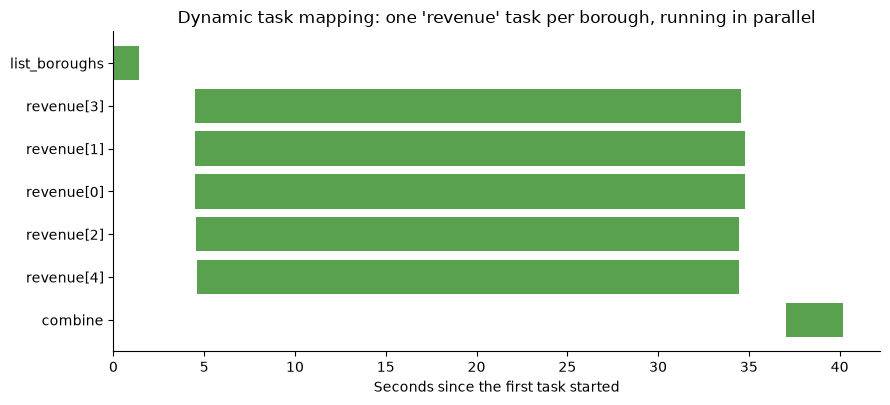

In [2]:
deploy("taxi_by_borough", f"""
from datetime import datetime
from airflow.sdk import dag, task

DATA = "{DATA_IN_CONTAINER}"

@dag(schedule=None, start_date=datetime(2024, 1, 1), catchup=False, tags=["course", "m11"])
def taxi_by_borough():

    @task
    def list_boroughs() -> list[str]:
        import duckdb
        rows = duckdb.execute(f"SELECT DISTINCT Borough FROM read_csv_auto('{{DATA}}/taxi_zone_lookup.csv') "
                              "WHERE Borough NOT IN ('Unknown', 'N/A', 'EWR') ORDER BY 1").fetchall()
        return [r[0] for r in rows]

    @task
    def revenue(borough: str) -> dict:
        import duckdb
        rev, trips = duckdb.execute(f\"\"\"
            SELECT sum(t.total_amount), count(*) FROM read_parquet('{{DATA}}/yellow_tripdata_2024-01.parquet') t
            JOIN read_csv_auto('{{DATA}}/taxi_zone_lookup.csv') z ON z.LocationID = t.PULocationID
            WHERE z.Borough = ? AND t.fare_amount BETWEEN 3 AND 500\"\"\", [borough]).fetchone()
        return {{"borough": borough, "revenue": round(rev or 0, 2), "trips": trips}}

    @task
    def combine(results: list[dict]) -> dict:
        total = sum(r["revenue"] for r in results)
        return {{r["borough"]: round(100 * r["revenue"] / total, 2) for r in results}}

    combine(revenue.expand(borough=list_boroughs()))

taxi_by_borough()
""")
run_id = trigger("taxi_by_borough")
print("state:", wait("taxi_by_borough", run_id))
ti = tasks("taxi_by_borough", run_id)
print(ti[["task_id", "map_index", "state"]].to_string(index=False))
print("\nrevenue share % per borough:", xcom("taxi_by_borough", run_id, "combine"))
gantt(ti, "Dynamic task mapping: one 'revenue' task per borough, running in parallel")

## 2. Branching, Trigger Rules and Retries

- `@task.branch` returns the task id(s) to follow; the other paths are **skipped**.
- A task after a branch needs a **trigger rule** such as `none_failed_min_one_success`, otherwise the skipped path would skip it too.
- A task with `retries=3` that fails temporarily succeeds on a later try. The flaky task below fails on its first try on purpose.

In [3]:
deploy("branching_and_retries", """
from datetime import datetime, timedelta
from airflow.sdk import dag, task, get_current_context

@dag(schedule=None, start_date=datetime(2024, 1, 1), catchup=False, tags=["course", "m11"])
def branching_and_retries():

    @task.branch
    def choose(**context) -> str:
        day = context["dag_run"].conf.get("day", "2024-01-15")
        weekday = datetime.fromisoformat(day).weekday()
        return "weekend_report" if weekday >= 5 else "weekday_report"

    @task
    def weekday_report():
        return "full operations report"

    @task
    def weekend_report():
        return "short weekend report"

    @task(retries=3, retry_delay=timedelta(seconds=3), trigger_rule="none_failed_min_one_success")   # runs after either branch
    def flaky_upload():
        ti = get_current_context()["ti"]
        if ti.try_number < 2:
            raise ConnectionError("simulated network glitch")
        return f"uploaded on try {ti.try_number}"

    @task(trigger_rule="none_failed_min_one_success")
    def notify(result: str | None = None):
        return f"done: {result}"

    branch = choose()
    w, e = weekday_report(), weekend_report()
    up = flaky_upload()
    branch >> [w, e] >> up
    notify(up)

branching_and_retries()
""")
results = {}
for day in ["2024-01-15", "2024-01-20"]:                      # a Monday and a Saturday
    rid = trigger("branching_and_retries", conf={"day": day})
    results[day] = (rid, wait("branching_and_retries", rid))
for day, (rid, state) in results.items():
    ti = tasks("branching_and_retries", rid)
    print(f"{day} ({pd.Timestamp(day).day_name()}): run {state}")
    print("  " + ti[["task_id", "state", "try_number"]].to_string(index=False).replace("\n", "\n  "))
    print("  notify ->", xcom("branching_and_retries", rid, "notify"))

2024-01-15 (Monday): run success
         task_id   state  try_number
          choose success           1
  weekend_report skipped           0
  weekday_report success           1
    flaky_upload success           2
          notify success           1
  notify -> done: uploaded on try 2
2024-01-20 (Saturday): run success
         task_id   state  try_number
          choose success           1
  weekday_report skipped           0
  weekend_report success           1
    flaky_upload success           2
          notify success           1
  notify -> done: uploaded on try 2


On Monday the weekend path is skipped, on Saturday the weekday path; in both runs the flaky upload fails on try 1 and succeeds on try 2, and `notify` still runs thanks to its trigger rule.

## 3. Sensors: Wait for an External Event

A **sensor** waits until a condition is true: a file exists, a partition is in the warehouse, an API reports "ready". In `mode="reschedule"`, the sensor frees its worker slot between checks (deferrable operators go further and hand the wait to the triggerer). The demo DAG waits for a file that the notebook creates a few seconds after triggering.

In [4]:
deploy("wait_for_delivery", """
from datetime import datetime
from airflow.sdk import dag, task
from airflow.providers.standard.sensors.python import PythonSensor

def delivery_arrived():
    import os
    return os.path.exists("/opt/airflow/output/delivery_2024-02.ready")

@dag(schedule=None, start_date=datetime(2024, 1, 1), catchup=False, tags=["course", "m11"])
def wait_for_delivery():
    wait_file = PythonSensor(task_id="wait_for_file", python_callable=delivery_arrived, poke_interval=5,
                             timeout=300, mode="reschedule")

    @task
    def process():
        return "February delivery processed"

    wait_file >> process()

wait_for_delivery()
""")
flag = OUT / "delivery_2024-02.ready"
flag.unlink(missing_ok=True)
rid = trigger("wait_for_delivery")
time.sleep(15)
before = tasks("wait_for_delivery", rid)
print("15 s after the trigger:", dict(zip(before["task_id"], before["state"])))
flag.write_text("ok")                                          # the "upstream system" delivers the file
print("state after delivery:", wait("wait_for_delivery", rid))
print(tasks("wait_for_delivery", rid)[["task_id", "state", "try_number"]].to_string(index=False))

15 s after the trigger: {'wait_for_file': 'up_for_reschedule', 'process': nan}


state after delivery: success
      task_id   state  try_number
wait_for_file success           1
      process success           1


## 4. Backfills

A **backfill** runs a DAG for past data intervals, for example after fixing a bug or adding a new DAG. In Airflow 3, backfills are created by the **scheduler** through the API (or `airflow backfill create`), and their runs appear in the UI like scheduled runs.

In [5]:
deploy("daily_partition", f"""
from datetime import datetime
from airflow.sdk import dag, task

DATA = "{DATA_IN_CONTAINER}"

@dag(schedule="@daily", start_date=datetime(2024, 2, 1), catchup=False, max_active_runs=3, tags=["course", "m11"])
def daily_partition():

    @task
    def count_day(**context) -> dict:
        import duckdb
        day = context["data_interval_start"].strftime("%Y-%m-%d")
        n = duckdb.execute(f"SELECT count(*) FROM read_parquet('{{DATA}}/yellow_tripdata_2024-02.parquet') "
                           f"WHERE CAST(tpep_pickup_datetime AS DATE) = DATE '{{day}}'").fetchone()[0]
        return {{"day": day, "trips": n}}

    count_day()

daily_partition()
""")
# start from a clean state, so the notebook can be re-run: remove earlier runs of this DAG
for old in requests.get(f"{API}/dags/daily_partition/dagRuns", params={"limit": 100}, timeout=10).json()["dag_runs"]:
    requests.delete(f"{API}/dags/daily_partition/dagRuns/{old['dag_run_id']}", timeout=10)
bf = requests.post(f"{API}/backfills", json={"dag_id": "daily_partition", "from_date": "2024-02-01T00:00:00Z",
                                             "to_date": "2024-02-07T00:00:00Z", "max_active_runs": 3, "reprocess_behavior": "none"},
                   timeout=10)
info = bf.json() if bf.headers.get("content-type", "").startswith("application/json") else {"detail": bf.text[:200]}
print("backfill:", bf.status_code, {k: info.get(k) for k in ["id", "from_date", "to_date", "detail"] if k in info})
deadline = time.time() + 300
while time.time() < deadline:
    runs = requests.get(f"{API}/dags/daily_partition/dagRuns", params={"limit": 50}, timeout=10).json()["dag_runs"]
    bruns = [r for r in runs if r.get("run_type") == "backfill"]
    if bruns and all(r["state"] in ("success", "failed") for r in bruns) and len(bruns) >= 6:
        break
    time.sleep(5)
rows = [{"interval_start": r["data_interval_start"][:10], "state": r["state"],
         "trips": (xcom("daily_partition", r["dag_run_id"], "count_day") or {}).get("trips")} for r in bruns]
pd.DataFrame(rows).sort_values("interval_start")

backfill: 200 {'id': 1, 'from_date': '2024-02-01T00:00:00Z', 'to_date': '2024-02-07T00:00:00Z'}


,interval_start,state,trips
0,2024-02-01,success,109994
1,2024-02-02,success,105470
2,2024-02-03,success,110603
3,2024-02-04,success,88091
4,2024-02-05,success,88421
5,2024-02-06,success,102152
6,2024-02-07,success,102971


| Pattern | Use |
| :--- | :--- |
| dynamic task mapping | one task per file, partition, customer, model — decided at runtime |
| branching + trigger rules | different processing per condition; joins after optional paths |
| retries | temporary failures (network, locks, rate limits) |
| sensors / deferrable operators | wait for files, partitions, external jobs, without blocking workers |
| backfills | re-run history after fixes or for new pipelines |
| pools, `max_active_runs` | protect shared resources (a database, an API quota) |

*Insight: Model real-world uncertainty explicitly in the DAG: fan out over what you discover at runtime, branch on conditions, retry what can fail temporarily, wait for what arrives late, and backfill history through the scheduler instead of by hand.*

## Real-World Use Case or Analogy

A sensor is like a **courier waiting at reception for a parcel**: they check every few minutes instead of blocking the entrance (reschedule mode). Dynamic mapping is like **sending one courier per parcel** when you only learn in the morning how many parcels there are.

Data teams use mapped tasks to process "all new files in the bucket", sensors to wait for partner deliveries, and backfills after every logic change in a fact table.